In [21]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')
import torchvision
import torchvision.transforms as transforms
from pdm_model import Net, SimpleNet, EI_Linear

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


In [22]:
# MNIST_MEAN = 0.1307
# MNIST_STD = 0.3081

# mnist_transforms = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MNIST_MEAN,), (MNIST_STD,))])
# train_dataset = torchvision.datasets.MNIST('.', train=True, download=True, transform=mnist_transforms)
# test_dataset = torchvision.datasets.MNIST('.', train=False, download=True, transform=mnist_transforms)


# mean = (0.4914, 0.4822, 0.4465)
# std = (0.2471, 0.2435, 0.2616)
# transform = transforms.Compose(
#     [
#         transforms.ToTensor(),
#         transforms.Normalize(mean, std),
#     ]
# )
# train_dataset = torchvision.datasets.CIFAR10('.', train=True, download=True, transform=transform)
# test_dataset = torchvision.datasets.CIFAR10('.', train=False, download=True, transform=transform)


# Create datasets


In [23]:
class ParityDataset(Dataset):
    def __init__(self, seq_len=64, num_samples=100000):
        self.seq_len = seq_len
        self.num_samples = num_samples
        vector = 2 * torch.randint(0, 2, (self.num_samples, self.seq_len)) - 1
        self.data = vector.float()
        negatives = (vector == -1).to(torch.long)
        cumsum = torch.cumsum(negatives, dim=-1)
        self.target = (cumsum % 2 != 0).to(torch.long).squeeze(-2)

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.target[idx]

# Create datasets
# train_dataset = ParityDataset(seq_len=15, num_samples=50000)
# test_dataset = ParityDataset(seq_len=15, num_samples=1000)

In [24]:
class SortDataset(Dataset):
    def __init__(self, seq_len=64, num_samples=100000):
        self.seq_len = seq_len
        self.num_samples = num_samples
        number = torch.rand(num_samples, seq_len)
        argsort = torch.argsort(number, dim=1)
        # argsort_till_t = torch.zeros(num_samples, seq_len, seq_len)
        # for i in range(seq_len):
        #     argsort_till_t[:, i, :i+1] = torch.argsort(number[:, :i+1], dim=1, descending=False)
        #     argsort_till_t[:, i, i+1:] = -11  # padding with -1
        # self.argsort_till_t = argsort_till_t.to(torch.long)
        self.data = number
        self.target = argsort

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.target[idx]
train_dataset = SortDataset(seq_len=5, num_samples=50000)
test_dataset = SortDataset(seq_len=5, num_samples=1000)

In [25]:

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Show example
sample_input, sample_target = train_dataset[0]
print(f"\nExample input shape: {sample_input}")
print(f"Example target: {sample_target}")

Training dataset size: 50000
Test dataset size: 1000

Example input shape: tensor([0.7530, 0.1287, 0.4961, 0.6720, 0.4480])
Example target: tensor([1, 4, 2, 3, 0])


In [26]:
# Visualize the MNIST dataset
# n = 10
# idx = np.random.randint(0, len(train_dataset), size=n)
# fig, ax = plt.subplots(1, n, figsize=(n, 1.5))
# for i in range(n):
#     image, label = train_dataset[idx[i]]
#     ax[i].imshow(image.view(3,32,32).transpose(1,0).transpose(1,2))
#     ax[i].set_title(f"Label: {label}")
#     ax[i].axis('off')
# plt.show()

In [27]:
class EI_FFN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, entropy_loss=True):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.f1 = nn.Linear(input_size, hidden_size)
        self.act1 = nn.Softplus()
        self.f2 = EI_Linear(hidden_size, hidden_size)
        self.act2 = nn.Softplus()
        self.f3 = nn.Linear(hidden_size, output_size)
        self.entropy_loss = entropy_loss

    def forward(self, x):
        x1 = self.act1(self.f1(x))
        x = self.act2(self.f2(x1)) + x1
        return self.f3(x)

    def get_ei_entropy_loss(self):
        entropy_loss = 0.0
        for m in [self.f1, self.f2]:
            if isinstance(m, EI_Linear):
                entropy_loss += m.get_ei_entropy_loss()
        return entropy_loss


class FFN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, entropy_loss=False):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.f1 = nn.Linear(input_size, hidden_size)
        self.act1 = nn.Softplus()
        self.f2 = nn.Linear(hidden_size, hidden_size)
        self.act2 = nn.Softplus()
        self.f3 = nn.Linear(hidden_size, output_size)

        self.entropy_loss = entropy_loss

    def forward(self, x):
        x1 = self.act1(self.f1(x))
        x = self.act2(self.f2(x1)) + x1
        return self.f3(x)


In [28]:
def train_model(model, train_loader, test_loader, epochs=100, lr=0.001):
    """
    Train a model on the adding problem.
    """
    if isinstance(model, Net):
        special_params, other_params = [], []
        for name, p in model.named_parameters():
            if name == "lstm.eimask_logit":   # 或者用 name.endswith("eimask_logit")
                special_params.append(p)
                # assert p.requires_grad, "eimask_logit should be trainable"
            else:
                other_params.append(p)
        optimizer = torch.optim.Adam([{'params': special_params, 'lr': lr},
                                      {'params': other_params, 'lr': lr}])
    else:
        special_params, other_params = [], []
        for name, p in model.named_parameters():
            if "eimask_logit" in name:   # 或者用 name.endswith("eimask_logit")
                special_params.append(p)
                # assert p.requires_grad, "eimask_logit should be trainable"
            else:
                other_params.append(p)
        optimizer = torch.optim.Adam([{'params': special_params, 'lr': 100*lr},
                                      {'params': other_params, 'lr': lr}])
        # For SimpleNet, use a single learning rate
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()  # Use CrossEntropyLoss for classification

    train_losses = torch.zeros(epochs)
    test_every = 100
    test_losses = torch.zeros(epochs // test_every)

    model.train()

    for epoch in range(epochs):
        # print(epoch)
        # Training
        # if isinstance(model, Net):
            # if epoch % 100 == 0:
            #     print(f"Epoch {epoch}: Temperature = {model.temperature:.4f}")
            #     eimask = model.lstm.eimask_logit.detach().cpu().numpy()
            #     fig, ax = plt.subplots(1,1,figsize=(8, 2))
            #     ax.plot(eimask[:, 0], label='Excitatory', color='C1')
            #     ax.plot(eimask[:, 1], label='Inhibitory', color='C0')
            #     ax.set_title('EI mask')
            #     ax.set_xlabel('Neuron index')
            #     ax.set_ylabel('Logit value')
            #     ax.legend()
            #     plt.show()
            #     plt.close()
        total_train_loss = 0
        num_batches = 0

        # for batch_inputs, batch_targets in train_loader:
        batch_inputs, batch_targets = next(iter(train_loader))
        # print('batch_inputs:', batch_inputs.shape)
        batch_inputs = batch_inputs.to(device)  # (batch_size, input_size)
        # print('batch_targets:', batch_targets.shape)
        batch_targets = batch_targets.to(device)
        B, O = batch_targets.shape

        optimizer.zero_grad()

        # Forward pass
        outputs = model(batch_inputs)

        # Use the last output for regression
        predictions = outputs.reshape(B, O, O).flatten(0,1)
        # print('predictions:', predictions.shape)
        # print('targets:', batch_targets.shape)
        decoding_loss = criterion(predictions, batch_targets.flatten())

        if model.entropy_loss:
            entropy_loss = model.get_ei_entropy_loss()
        else:
            entropy_loss = 0.0

        loss = 1 * entropy_loss + decoding_loss
        # Backward pass
        loss.backward()
        # Gradient clipping for stability
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        total_train_loss += loss.item()
        num_batches += 1

        avg_train_loss = total_train_loss / num_batches
        train_losses[epoch] = avg_train_loss

        # Testing
        if epoch % test_every == 0:
            model.eval()
            total_test_loss = 0
            total_test_acc = 0
            num_test_batches = 0

            with torch.no_grad():
                for batch_inputs, batch_targets in test_loader:
                    batch_inputs = batch_inputs.to(device)
                    batch_targets = batch_targets.to(device).flatten()

                    outputs = model(batch_inputs)
                    predictions = outputs.reshape(*batch_targets.shape, O)

                    loss = criterion(predictions, batch_targets)
                    total_test_loss += loss.item()
                    total_test_acc += (predictions.argmax(-1) == batch_targets).float().mean().item()
                    num_test_batches += 1

            avg_test_loss = total_test_loss / num_test_batches
            avg_test_acc = total_test_acc / num_test_batches
            test_losses[epoch // test_every] = avg_test_loss

            print(f'Epoch [{epoch:4d}/{epochs}], Train Loss: {avg_train_loss:.6f}, Test Loss: {avg_test_loss:.6f}, Test Acc: {avg_test_acc:.4f}')

            model.train()

    return train_losses, test_losses

def evaluate_model(model, test_loader):
    """
    Evaluate model performance on test set.
    """
    model.eval()
    total_loss = 0
    predictions = []
    targets = []

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for batch_inputs, batch_targets in test_loader:
            batch_inputs = batch_inputs.to(device)
            batch_targets = batch_targets.to(device).flatten()

            outputs = model(batch_inputs)
            preds = outputs.reshape(*batch_targets.shape, batch_inputs.shape[-1])

            loss = criterion(preds, batch_targets)
            total_loss += loss.item()

            predictions.extend(preds.cpu().numpy())
            targets.extend(batch_targets.cpu().numpy())

    avg_loss = total_loss / len(test_loader)
    acc = np.mean(np.array(predictions).argmax(-1) == np.array(targets))

    return avg_loss, acc, predictions, targets

In [29]:
# Experiment parameters
n_seeds = 5
epochs = 3000
batch_size = 256
hidden_size = 64
input_size = 5  # [number, indicator]
output_size = 25  # regression output

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Storage for results
results = {
    'net': {'train_losses': [], 'test_losses': [], 'final_acc':[]},
    'simple': {'train_losses': [], 'test_losses': [], 'final_acc':[]}
}

print(f"Running experiment with {n_seeds} seeds...\n")
lr_ei = 1e-2
lr_simple = 1e-2
for seed in range(n_seeds):
    print(f"=== Seed {seed + 1}/{n_seeds} ===")

    # Set random seeds for reproducibility
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Train Net (EI-separated RNN)
    print("Training Net...")
    net = EI_FFN(input_size, hidden_size, output_size, entropy_loss=True).to(device)

    train_losses_net, test_losses_net = train_model(net, train_loader, test_loader, epochs=epochs, lr=lr_ei)

    # Evaluate Net
    _, acc_net, net_predictions, net_targets = evaluate_model(net, test_loader)

    results['net']['train_losses'].append(train_losses_net)
    results['net']['test_losses'].append(test_losses_net)
    results['net']['final_acc'].append(acc_net)
    print(f"Net - Final Acc: {acc_net:.6f}")

    print("Training SimpleNet...")
    simple_net = FFN(input_size, hidden_size, output_size).to(device)
    train_losses_simple, test_losses_simple = train_model(simple_net, train_loader, test_loader, epochs=epochs,lr=lr_simple)

    # Evaluate SimpleNet
    _, acc_simple, simple_predictions, simple_targets = evaluate_model(simple_net, test_loader)

    results['simple']['train_losses'].append(train_losses_simple.detach().cpu().numpy())
    results['simple']['test_losses'].append(test_losses_simple.detach().cpu().numpy())
    results['simple']['final_acc'].append(acc_simple)

    print(f"SimpleNet - Final Acc: {acc_simple:.6f}")




print("Experiment completed!")

Running experiment with 5 seeds...

=== Seed 1/5 ===
Training Net...
Epoch [   0/3000], Train Loss: 2.368279, Test Loss: 1.819726, Test Acc: 0.1957
Epoch [ 100/3000], Train Loss: 1.444093, Test Loss: 1.129349, Test Acc: 0.4170
Epoch [ 200/3000], Train Loss: 1.097492, Test Loss: 0.975112, Test Acc: 0.4914
Epoch [ 300/3000], Train Loss: 0.919394, Test Loss: 0.858552, Test Acc: 0.5440
Epoch [ 400/3000], Train Loss: 0.782761, Test Loss: 0.711042, Test Acc: 0.6896
Epoch [ 500/3000], Train Loss: 0.541281, Test Loss: 0.541662, Test Acc: 0.7717
Epoch [ 600/3000], Train Loss: 0.587874, Test Loss: 0.483059, Test Acc: 0.8048
Epoch [ 700/3000], Train Loss: 0.498344, Test Loss: 0.475945, Test Acc: 0.8015
Epoch [ 800/3000], Train Loss: 0.408198, Test Loss: 0.396665, Test Acc: 0.8411
Epoch [ 900/3000], Train Loss: 0.394263, Test Loss: 0.384114, Test Acc: 0.8408
Epoch [1000/3000], Train Loss: 0.385025, Test Loss: 0.365350, Test Acc: 0.8477
Epoch [1100/3000], Train Loss: 0.340098, Test Loss: 0.332335, 

In [30]:
# Print summary statistics
print("=== Final Results Summary ===")
print(f"Number of seeds: {n_seeds}")
print(f"Training epochs: {epochs}")
print(f"Hidden size: {hidden_size}")
print()

# Net results
net_acc_mean = np.mean(results['net']['final_acc'])
net_acc_std = np.std(results['net']['final_acc'])
simple_acc_mean = np.mean(results['simple']['final_acc'])
simple_acc_std = np.std(results['simple']['final_acc'])

print(f"Net (EI-separated RNN):")
print(f"  Acc: {net_acc_mean:.6f} ± {net_acc_std:.6f}")

print(f"\nSimpleNet (vanilla RNN):")
print(f"  Acc: {simple_acc_mean:.6f} ± {simple_acc_std:.6f}")

# Improvement calculation
acc_improvement = (net_acc_mean - simple_acc_mean ) / simple_acc_mean * 100

print(f"\n=== Performance Comparison ===")
print(f"Acc improvement (Net vs SimpleNet): {acc_improvement:.2f}%")

if acc_improvement > 0:
    print("Net (EI-separated) performs better than SimpleNet (vanilla RNN)")
else:
    print("SimpleNet (vanilla RNN) performs better than Net (EI-separated)")

=== Final Results Summary ===
Number of seeds: 5
Training epochs: 3000
Hidden size: 64

Net (EI-separated RNN):
  Acc: 0.929520 ± 0.005436

SimpleNet (vanilla RNN):
  Acc: 0.951880 ± 0.002992

=== Performance Comparison ===
Acc improvement (Net vs SimpleNet): -2.35%
SimpleNet (vanilla RNN) performs better than Net (EI-separated)


net train mean: [2.431413   2.2969356  2.2782078  ... 0.17828125 0.17881833 0.17521569]
(array([], dtype=int64), array([], dtype=int64))


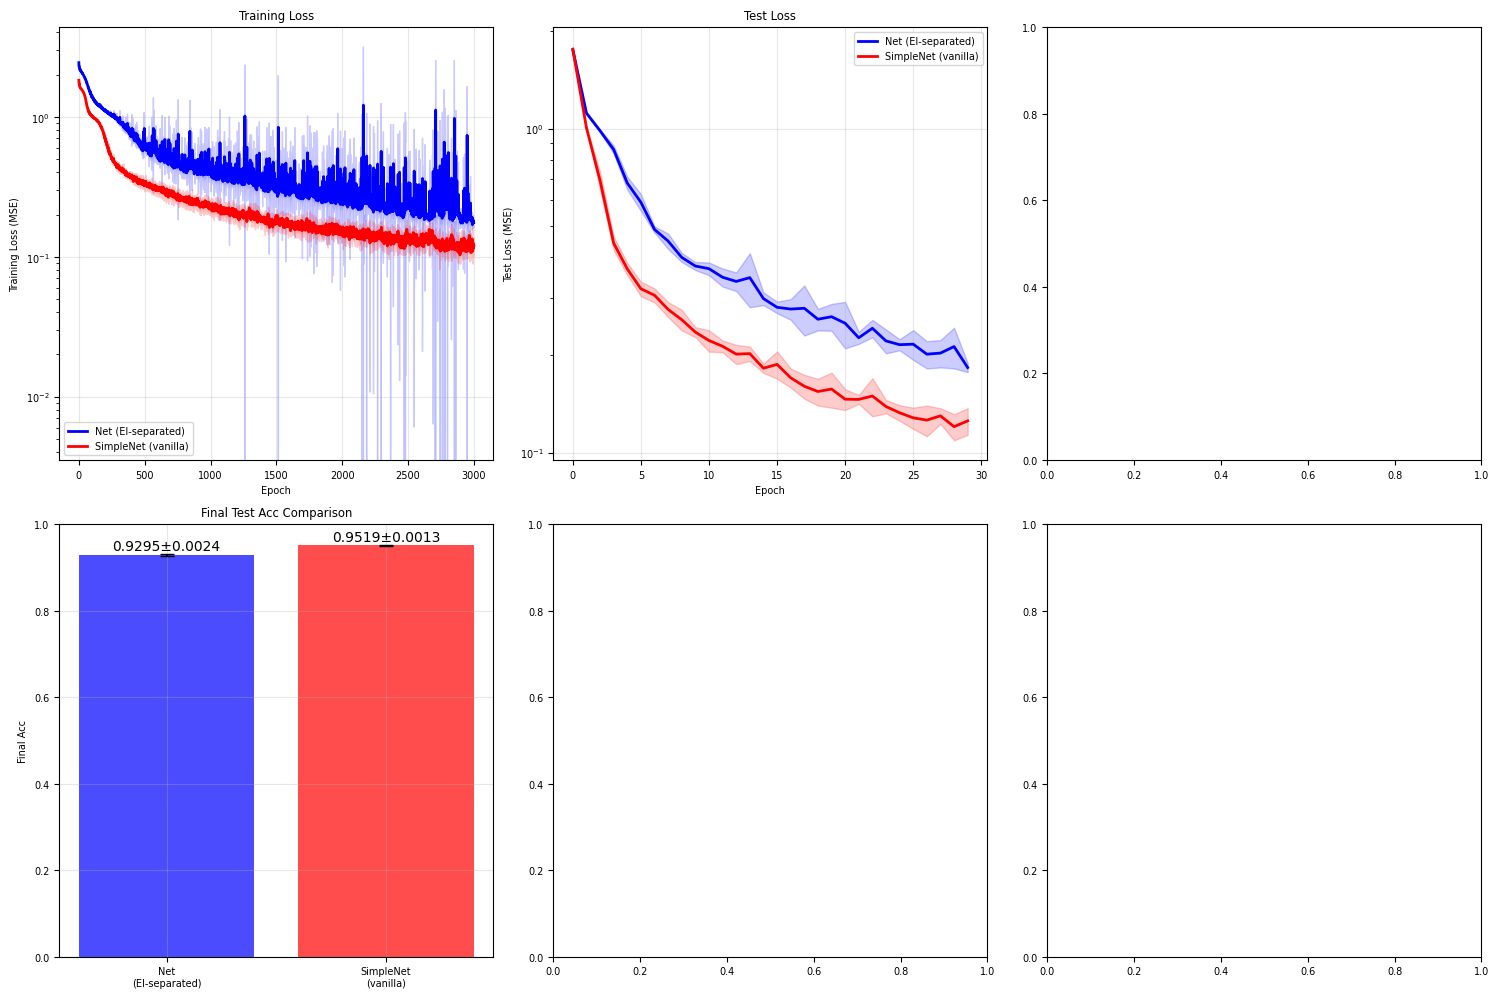

In [31]:
def plot_learning_curves(results, n_seeds):
    """
    Plot learning curves for both models.
    """
    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(15, 10))

    # Training loss curves
    net_train_losses = np.array(results['net']['train_losses'])
    simple_train_losses = np.array(results['simple']['train_losses'])

    net_train_mean = np.mean(net_train_losses, axis=0)
    net_train_std = np.std(net_train_losses, axis=0)
    simple_train_mean = np.mean(simple_train_losses, axis=0)
    simple_train_std = np.std(simple_train_losses, axis=0)
    print('net train mean:', net_train_mean)
    print(np.where(net_train_losses>100))

    epochs_range = range(len(net_train_mean))

    ax1.plot(epochs_range, net_train_mean, 'b-', label='Net (EI-separated)', linewidth=2)
    ax1.fill_between(epochs_range, net_train_mean - net_train_std, net_train_mean + net_train_std, alpha=0.2, color='blue')
    ax1.plot(epochs_range, simple_train_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax1.fill_between(epochs_range, simple_train_mean - simple_train_std, simple_train_mean + simple_train_std, alpha=0.2, color='red')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss (MSE)')
    ax1.set_title('Training Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_yscale('log')

    # Test loss curves (subset of epochs)
    if results['net']['test_losses'][0] is not None:  # Check if test losses exist
        net_test_losses = np.array(results['net']['test_losses'])
        simple_test_losses = np.array(results['simple']['test_losses'])

        net_test_mean = np.mean(net_test_losses, axis=0)
        net_test_std = np.std(net_test_losses, axis=0)
        simple_test_mean = np.mean(simple_test_losses, axis=0)
        simple_test_std = np.std(simple_test_losses, axis=0)

        test_epochs = range(0, len(net_train_mean))[:len(net_test_mean)]

        ax2.plot(test_epochs, net_test_mean, 'b-', label='Net (EI-separated)', linewidth=2)
        ax2.fill_between(test_epochs, net_test_mean - net_test_std, net_test_mean + net_test_std, alpha=0.2, color='blue')
        ax2.plot(test_epochs, simple_test_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
        ax2.fill_between(test_epochs, simple_test_mean - simple_test_std, simple_test_mean + simple_test_std, alpha=0.2, color='red')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Test Loss (MSE)')
        ax2.set_title('Test Loss')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.set_yscale('log')


    # Final Acc comparison
    net_acc = results['net']['final_acc']
    simple_acc = results['simple']['final_acc']

    x_pos = [0, 1]
    acc_means = [np.mean(net_acc), np.mean(simple_acc)]
    acc_stds = [np.std(net_acc)/np.sqrt(len(net_acc)), np.std(simple_acc)/np.sqrt(len(simple_acc))]

    bars = ax4.bar(x_pos, acc_means, yerr=acc_stds, capsize=5,
                   color=['blue', 'red'], alpha=0.7,
                   label=['Net (EI-separated)', 'SimpleNet (vanilla)'])
    ax4.set_ylabel('Final Acc')
    ax4.set_title('Final Test Acc Comparison')
    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(['Net\n(EI-separated)', 'SimpleNet\n(vanilla)'])
    ax4.grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (bar, mean, std) in enumerate(zip(bars, acc_means, acc_stds)):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.001,
                f'{mean:.4f}±{std:.4f}', ha='center', va='bottom', fontsize=10)


    plt.tight_layout()
    plt.show()

# Plot the results
plot_learning_curves(results, n_seeds)